In [1]:
import numpy as np
import matplotlib.pyplot as plt
import importlib
import stochastic_model_v1 as mfa

well depth =  7.2
well curvature =  0.96
deltaT = 13.4


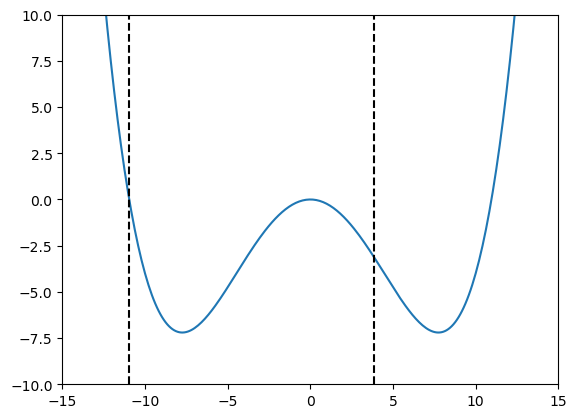

In [2]:
importlib.reload(mfa)

#MTD parameters
#simulation parameter
T = 1
#k_B = 1 assumed here

dw1 = mfa.double_well_1(0.002,120)

print("well depth = ", dw1.depth())

print("well curvature = ", dw1.sec_deriv_bottom())

deltaT = 2*dw1.depth()-T
print(f"deltaT = {deltaT}")

padfactor = 4
n_bins = 300
x = np.linspace(-padfactor*dw1.stdev(), padfactor*dw1.stdev(), n_bins)
F = dw1.f1(x)

plt.plot(x,F)
plt.axvline(dw1.stdev(), linestyle="dashed", color="black")
plt.axvline(dw1.xlim(), linestyle="dashed", color="black")
plt.ylim(-10,10)
plt.xlim(-15,15)

sysname = "double_well_1"

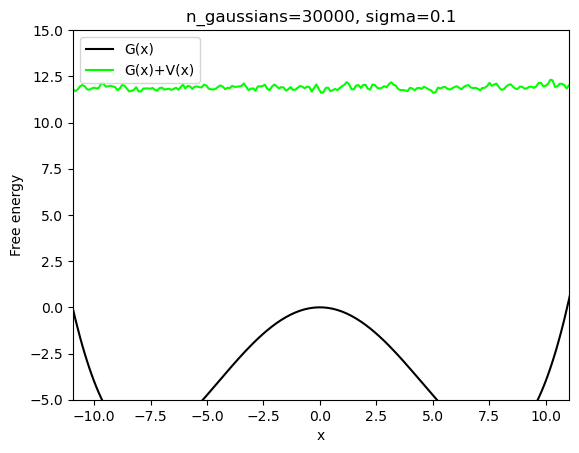

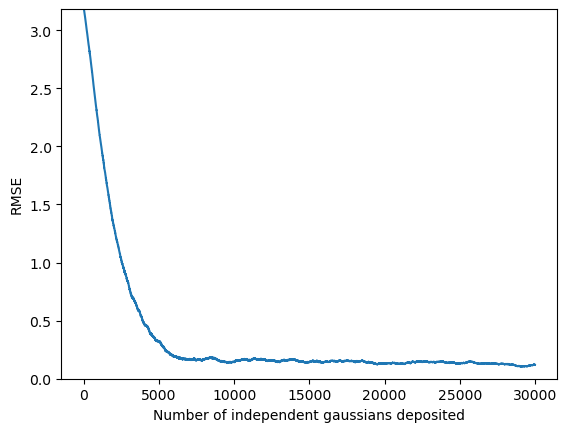

In [3]:
importlib.reload(mfa)

test_system = dw1

sigma = 0.1
omega = 0.2
nrounds = 30000
plot_output = True

rmse, V, lim_ind = mfa.simulate_v2(test_system, T, sigma, omega, deltaT, x=x, nrounds=nrounds, plot=plot_output)


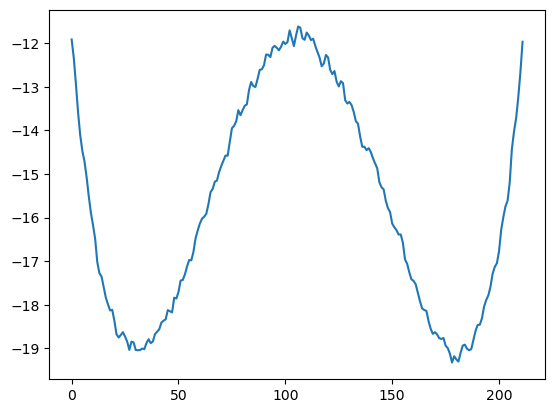

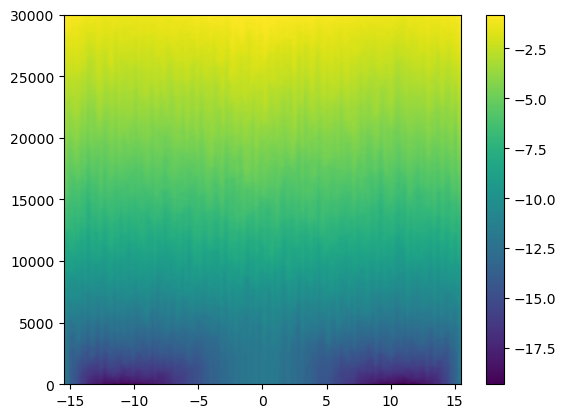

/tmp/ipykernel_29092/2297158032.py:28: RuntimeWarning: divide by zero encountered in divide
  plt.scatter(t[1:], 1/(deltaT/dcdt-t[1:]), label="dcdt", s=0.1)


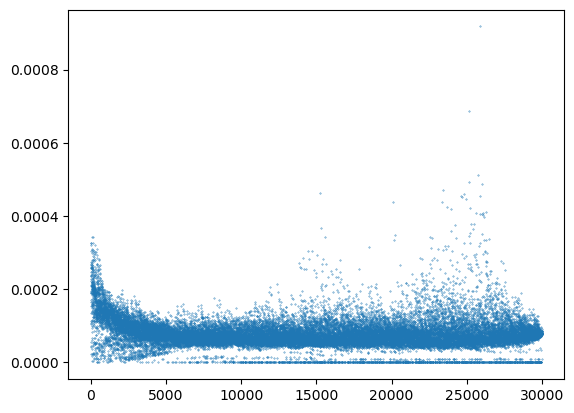

/tmp/ipykernel_29092/2297158032.py:32: RuntimeWarning: invalid value encountered in divide
  q = (np.exp(ct/deltaT)-1)/t


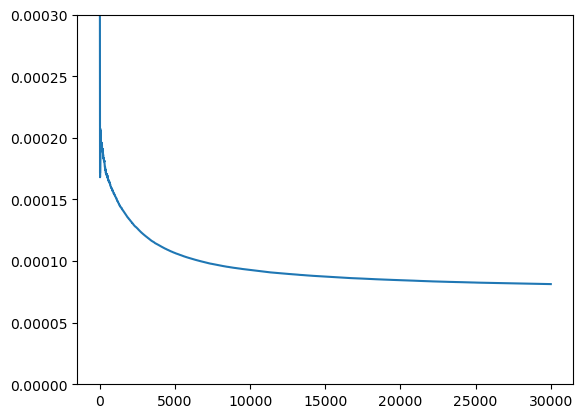

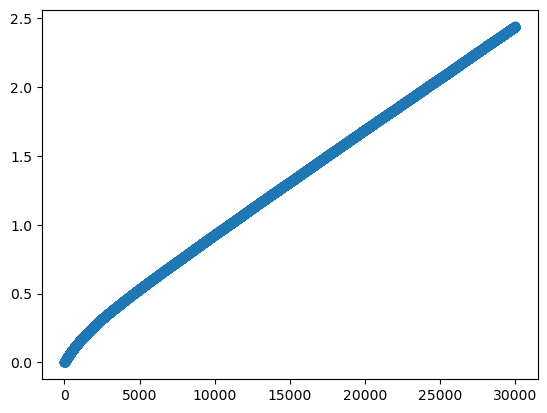

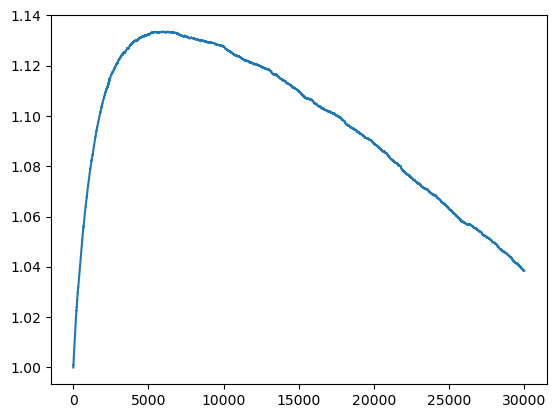

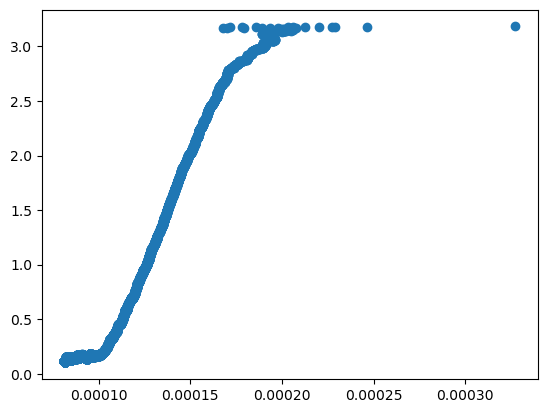

In [4]:
F_v = -V[-1, lim_ind:-lim_ind]*(T+deltaT)/deltaT
FpV = V[:, lim_ind:-lim_ind]+F_v

plt.plot(F_v)
plt.show()

# plt.imshow(F_v, extent=[x[0], x[-1], 0, nrounds], aspect='auto', origin='lower', cmap='viridis')
# plt.colorbar()
# plt.show()
plt.imshow(FpV, extent=[x[0], x[-1], 0, nrounds], aspect='auto', origin='lower', cmap='viridis')
plt.colorbar()
plt.show()

Z_0 = np.sum(np.exp(-F_v/T))
Z_V = np.sum(np.exp(-FpV/T), axis = 1)

ct = -T*np.log(Z_V/Z_0)

dct = np.diff(ct)

t = np.array([ti for ti in range(len(V))])

dt = np.diff(t)

dcdt = dct/dt

#plt.plot(1/(deltaT/dcdt-t[1:]), label="dcdt")
plt.scatter(t[1:], 1/(deltaT/dcdt-t[1:]), label="dcdt", s=0.1)

plt.show()

q = (np.exp(ct/deltaT)-1)/t

# plt.plot(Z_0, label="Z_0")
# plt.show()
# plt.plot(Z_V, label="Z_V")
# plt.show()
# plt.plot(ct, label="ct")
# plt.show()
plt.plot(q, label="q")
plt.ylim(0, 0.0003)
plt.show()
plt.scatter(t, np.exp(ct/deltaT)-1)
plt.show()

q2 = np.exp(ct/deltaT)-t*omega/(deltaT)*(Z_0**(T/deltaT))/(Z_V[-1]**(T/deltaT+1))
plt.plot(q2, label="q2")
plt.show()

plt.scatter(q[1:], rmse)

#for t in range(nrounds+1):
